# Train a CNN to classify the chess figures

Steps:
- Import image dataset with Keras
- Train a CNN
- Log training runs with mlflow

In [2]:
import os
import numpy as np
from tensorflow import keras
import matplotlib.pyplot as plt

2025-07-21 12:10:31.046111: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-21 12:10:31.061060: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-07-21 12:10:31.185064: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-07-21 12:10:31.289712: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753092631.382763    1068 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753092631.40

#### Define constants

Parameters necessary for the model training + boolean switch for mlflow logging.

In [17]:
# set image size
IMG_SIZE = 50

# set data directory
CURRENT_DIR = os.getcwd()
DATA_DIR = os.path.join(CURRENT_DIR, '..', 'data')
DATA_DIR = os.path.abspath(DATA_DIR)

# training parameters
BATCH_SIZE = 128
EPOCHS = 50

LOSS_FUNC = "categorical_crossentropy"
LEARNING_RATE = 0.01
MOMENTUM = 0.8
OPTIMIZER = keras.optimizers.SGD(learning_rate = LEARNING_RATE, momentum = MOMENTUM)
DROPOUT_RATE = 0.3

# switch for mlflow logging
MLFLOW_LOGGING = False

In [18]:
# Import training data

train_data = keras.utils.image_dataset_from_directory(
    # path to images
    directory = DATA_DIR,
    labels = 'inferred',              # labels are generated from the directory structure
    label_mode = 'categorical',       # 'categorical' => categorical cross-entropy
    color_mode = 'rgb',               # alternatives: 'grayscale', 'rgba';
    batch_size = BATCH_SIZE,
    image_size = (50, 50),
    shuffle = True,                   # shuffle images before each epoch
    seed = 0,                         # shuffle seed
    validation_split = 0.2,           # percentage of validation data
    subset = 'both',                  # return a tuple of datasets (train, val)
    interpolation = 'bilinear',       # interpolation method used when resizing images
    )

Found 10000 files belonging to 13 classes.
Using 8000 files for training.
Using 2000 files for validation.


In [19]:
# Check input shape, label shape & type, max pixel values

# load batch of images
batch = train_data[0].take(1)
input, label = list(batch)[0]

# convert to np arrays
input = input.numpy()
label = label.numpy()

print('batch shape (inputs) = ', input.shape) # batches of 128 50x50 rgb images
print('max pixel values = ', np.max(input)) # max = 255.0 => need rescaling later
print('pixel value data type = ', input.dtype) # float32
print()
print('batch shape (label) = ', label.shape) # 13 different classes, one-hot encoded
print('label data type = ', label.dtype) # float32

batch shape (inputs) =  (128, 50, 50, 3)
max pixel values =  255.0
pixel value data type =  float32

batch shape (label) =  (128, 13)
label data type =  float32


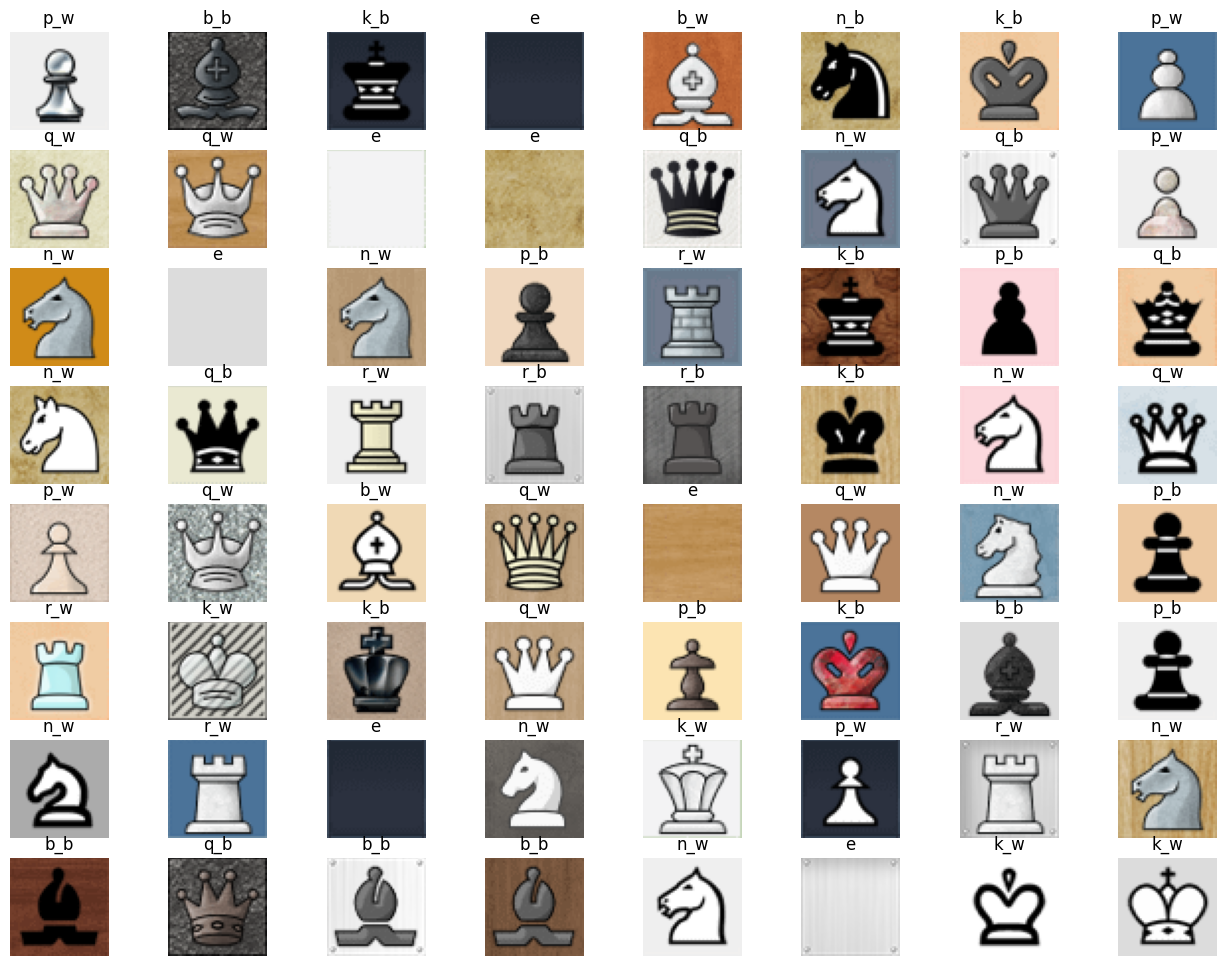

In [20]:
# Show a few chess piece images

plt.figure(figsize=(16, 12))
for images, labels in train_data[0]:
    for i in range(64):
        plt.subplot(8, 8, i+1)
        plt.imshow(images[i].numpy().astype(int))
        label = np.argmax(labels.numpy()[i])
        plt.title(train_data[0].class_names[label], fontsize=12)
        plt.axis('off')
    plt.show()
    break

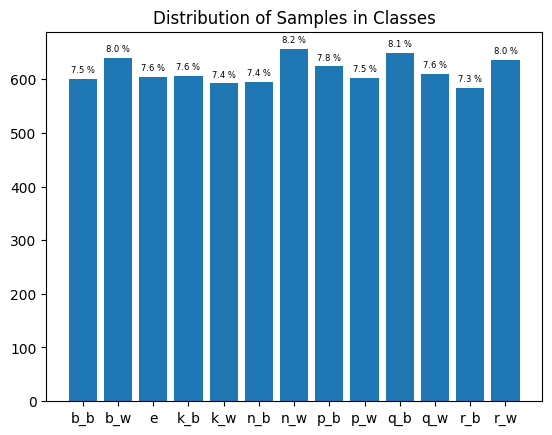

In [21]:
# Plot histogram to visualize class imbalance

all_labels = []
for x, y in train_data[0]:
    all_labels.append(np.argmax(y, axis = -1))
all_labels = np.concatenate(all_labels, axis = 0)


class_names_list = train_data[0].class_names

label_counts = [np.sum(all_labels == i) for i in range(len(class_names_list))]

plt.bar(class_names_list, label_counts)

for i in range(len(class_names_list)):
    plt.text(x = i, # x position of the text
             y = label_counts[i] + 12,  # y position of the text
             s = f'{round(100*label_counts[i] / len(all_labels),1)} %',
             ha = 'center',
             fontsize=6)
    
plt.title("Distribution of Samples in Classes")
#plt.yscale('log')
plt.show()

In [22]:
# Add class weights => maybe unnecessary for current balanced data, but good to have in case of inbalanced data

class_weights = 1/np.array(label_counts)
class_weights = class_weights/np.mean(class_weights)

class_weights_dict = dict(enumerate(class_weights))
class_weights_dict

{0: np.float64(1.02261727003718),
 1: np.float64(0.9603015301442894),
 2: np.float64(1.017538045186002),
 3: np.float64(1.0141798338157513),
 4: np.float64(1.038163816372205),
 5: np.float64(1.0329293769619248),
 6: np.float64(0.9368795416041849),
 7: np.float64(0.9849246463018353),
 8: np.float64(1.019225504630755),
 9: np.float64(0.9469845597724889),
 10: np.float64(1.0075294742497463),
 11: np.float64(1.0523852385142898),
 12: np.float64(0.9663411624093479)}

In [23]:
# build CNN

def get_model(dropout_rate): 
    
    # input => rgb
    inputs = keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    # Rescaling
    x = keras.layers.Rescaling(scale = 1./255)(inputs)
    
    # First block
    x = keras.layers.Conv2D(
        filters=18,
        kernel_size = (3,3),
        strides = (1,1),
        activation = 'relu',
        kernel_regularizer = None
        )(x) # output shape = (IMG_SIZE-2, IMG_SIZE-2, 18) = (48,48,18) 
    
    x = keras.layers.MaxPooling2D(pool_size=(3, 3))(x) # output shape = ((IMG_SIZE-2)/3, (IMG_SIZE-2)/3, 18) = (16,16,18) 
    
    # Second block 
    x = keras.layers.Conv2D(
        filters=36,
        kernel_size = (3,3),
        strides = (1,1),
        padding = 'same', # => output image has the same size as the input image
        activation = 'relu',
        kernel_regularizer = None
        )(x) # output shape = ((IMG_SIZE-2)/3, (IMG_SIZE-2)/3, 36) = (16,16,36)
    
    x = keras.layers.MaxPooling2D(pool_size=(4, 4))(x) # ((IMG_SIZE-2)/12, (IMG_SIZE-2)/12, 36) = (4,4,36)
    
    # Head (Flatten + Dense Layer)
    x = keras.layers.Flatten()(x) # output shape = 1/4 * (IMG_SIZE-2)^2 = 576
    x = keras.layers.Dense(64, activation="relu", kernel_regularizer = None)(x)
    
    if dropout_rate > 0:
        x = keras.layers.Dropout(dropout_rate)(x)

    #Final Layer (Output)
    output = keras.layers.Dense(13, activation='softmax')(x)
    
    model = keras.Model(inputs=inputs, outputs=output)
    
    return model

model = get_model(dropout_rate = 0)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 50, 50, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 50, 50, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 18)     │           504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 18)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 36)     │         5,868 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 36)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 13)             │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,145 (172.44 KB)

 Trainable params: 44,145 (172.44 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
metrics = ["accuracy"] # no f1_score b/c no class imbalance

# N.B. use class weights! in model.fit

model.compile(
    loss=LOSS_FUNC, 
    metrics = metrics,
    optimizer = OPTIMIZER
    )

history = model.fit(
    train_data[0], 
    epochs = EPOCHS, 
    verbose = True,
    class_weight = class_weights_dict,
    validation_data = train_data[1],
    )

Epoch 1/50


63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.1177 - loss: 2.5447 - val_accuracy: 0.3045 - val_loss: 2.3511
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.3609 - loss: 2.1442 - val_accuracy: 0.7185 - val_loss: 1.2214
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7431 - loss: 0.9978 - val_accuracy: 0.9075 - val_loss: 0.4478
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9160 - loss: 0.3662 - val_accuracy: 0.9240 - val_loss: 0.2769
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.9591 - loss: 0.1930 - val_accuracy: 0.9855 - val_loss: 0.1116
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9864 - loss: 0.0973 - val_accuracy: 0.9910 - val_loss: 0.0724
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9931 - loss: 0.0594 - val_accuracy: 0.9970 - val_loss: 0.0476
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9961 - loss: 0.0452 - val_accuracy: 0.9970 - val_loss: 0.